# 03 · Optimización del pedido y simulación de costos (Caso A)

**Objetivo.** Calcular cuánto pedir de cada producto en cada tienda para la semana del 1 al 7 de abril de 2024, minimizando el costo esperado de quedarse corto (Cu) y de pasarse (Co), y medir cuánto vale ese enfoque frente a reglas simples.

**Marco de decisión.** Newsvendor: se pide el cuantil τ = Cu / (Cu + Co) de la demanda durante el horizonte `lead time + revisión`, menos el stock y lo que viene en tránsito:

`pedido = máx(0, Q*(τ) − stock − en tránsito)`

**Qué no viene en los datos y se parametriza** (valor base declarado, rango probado, dato que habría que pedir al negocio): lead time, período de revisión, stock en tránsito, MOQ y empaque, capacidad de la tienda, merma (α) y venta cruzada perdida (β). Los valores base son supuestos, no datos; ver `ParametrosPedido` en `src/tostao_abastecimiento/optimizer.py` y el EDA (1.7, H9, H10, H13).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
if "DATA_DIR" not in globals():
    DATA_DIR = RAIZ / "data" / "01_supply_optimization"     # ver README: dónde colocar los datos

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from dataclasses import replace

from tostao_abastecimiento.config import ALFA_POR_PRODUCTO
from tostao_abastecimiento.optimizer import (IncertidumbreEmpirica, IncertidumbreNormal, ParametrosPedido,
                                             calcular_pedido, economia_producto)
from tostao_abastecimiento.pipeline import ejecutar_pipeline
from tostao_abastecimiento.sensibilidad import tabla_sensibilidad
from tostao_abastecimiento.data import cargar_caso_a
from tostao_abastecimiento.calibration import CalibradorCuantiles
from tostao_abastecimiento.validation import agregar_semanal
from tostao_abastecimiento.pipeline import MODELO_FINAL

In [3]:
datos = cargar_caso_a(DATA_DIR)
params = ParametrosPedido()                     # caso base declarado
res = ejecutar_pipeline(DATA_DIR, params)       # variables, backtest, calibración, pronóstico y pedido
print("Parámetros base:", {k: v for k, v in params.__dict__.items() if k != "alfa"})
print("α por producto:", params.alfa)

Parámetros base: {'lead_time_dias': 1, 'revision_dias': 7, 'en_transito_dias': 0.0, 'moq': 1, 'multiplo': 1, 'beta': 0.25, 'margen_cruzado': 2833.86, 'tau_min': 0.5, 'tau_max': 0.99, 'capacidad_tienda': None, 'cv_diario': 0.31}
α por producto: {'PROD_001': 0.25, 'PROD_002': 0.25, 'PROD_003': 0.25, 'PROD_004': 0.75, 'PROD_005': 1.0, 'PROD_006': 1.0, 'PROD_007': 0.5, 'PROD_008': 1.0}


## 1. Economía por producto: Cu, Co y ratio crítico

Cu = margen unitario + β × margen cruzado. Co = almacenamiento semanal + α × costo unitario. Con β = 25 % y los α declarados se obtiene el ratio crítico de cada producto: el cuantil de la demanda que hay que cubrir.

In [4]:
econ = economia_producto(datos.catalogo, params)
display(econ.round(3))

,id_producto,nombre,margen_unit,costo_unitario,cu,co,tau
0,PROD_001,Tinto,1700,800,"2,408.465",210.000,0.920
1,PROD_002,Café con Leche,2300,1200,"3,008.465",315.000,0.905
2,PROD_003,Cappuccino,3000,1500,"3,708.465",390.000,0.905
3,PROD_004,Pan de Bono,1800,1000,"2,508.465",770.000,0.765
4,PROD_005,Buñuelo,1700,800,"2,408.465",820.000,0.746
5,PROD_006,Croissant,2300,1200,"3,008.465","1,225.000",0.711
6,PROD_007,Pastel de Pollo,2000,1500,"2,708.465",780.000,0.776
7,PROD_008,Jugo de Naranja,3000,2000,"3,708.465","2,050.000",0.644


**Lectura.**

- **En todos los productos quedarse corto cuesta más que pasarse:** Cu de 2,408 a 3,708 frente a Co de 210 a 2,050. Por eso el ratio crítico τ es mayor que 0.5 en todos y el pedido apunta a un cuantil alto de la demanda, no a la media.
- **El ratio crítico va de 0.64 (Jugo de Naranja) a 0.92 (Tinto).** Los de bebidas calientes (Tinto, Café con Leche, Cappuccino) tienen τ ≈ 0.90–0.92 porque lo que sobra se pierde poco (α = 0.25) y su costo de almacenamiento es bajo. El Jugo de Naranja tiene el menor τ porque casi todo lo que sobra se pierde (α = 1) y es caro (costo unitario de 2,000 y almacenamiento de 50).
- **Entre los productos de panadería** τ queda entre 0.71 y 0.78 (Croissant 0.71, Buñuelo 0.75, Pan de Bono 0.77, Pastel de Pollo 0.78), según su α y su margen.
- **τ no depende de la tienda ni de la demanda,** solo de los costos de cada producto; la demanda entra después, en el cuantil. Como α y β son supuestos, estos τ también lo son: la sección 4 mide cuánto cambia el pedido si se mueven.

## 2. Pedido de la semana 1–7 de abril

El cuantil de la demanda se calcula con la incertidumbre calibrada en el backtest (distribución empírica de la venta relativa semanal). El pedido es el cuantil menos el stock actual, redondeado al empaque.

,id_tienda,id_producto,nombre,stock_actual,demanda_media_horizonte,tau,q_objetivo,pedido
0,STORE_01,PROD_001,Tinto,1,53.770,0.920,67.510,67.000
1,STORE_01,PROD_002,Café con Leche,10,70.310,0.910,84.120,75.000
2,STORE_01,PROD_003,Cappuccino,33,70.310,0.900,84.100,52.000
3,STORE_01,PROD_004,Pan de Bono,11,52.720,0.770,59.920,49.000
4,STORE_01,PROD_005,Buñuelo,3,85.810,0.750,93.860,91.000
5,STORE_01,PROD_006,Croissant,13,88.950,0.710,95.680,83.000
6,STORE_01,PROD_007,Pastel de Pollo,8,85.910,0.780,95.250,88.000
7,STORE_01,PROD_008,Jugo de Naranja,13,80.060,0.640,84.050,72.000
8,STORE_02,PROD_001,Tinto,9,81.610,0.920,98.700,90.000
9,STORE_02,PROD_002,Café con Leche,20,103.610,0.910,123.970,104.000


Pedido total: 15,453 u | demanda media del horizonte: 16,742 u | stock actual: 3,367 u
SKU-tienda sin pedido: 2 de 160


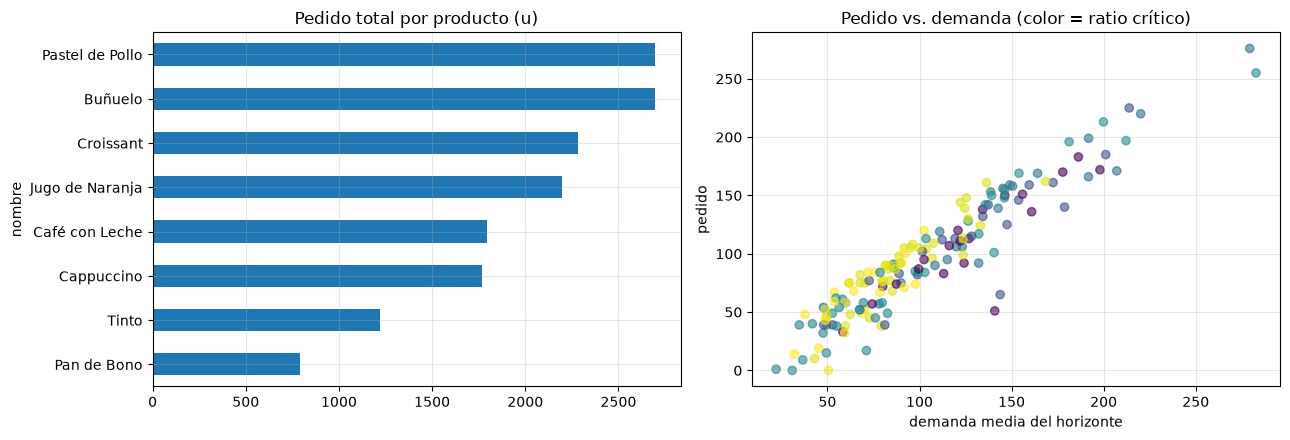

In [5]:
ped = res.pedido.copy()
cols = ["id_tienda", "id_producto", "nombre", "stock_actual", "demanda_media_horizonte", "tau", "q_objetivo", "pedido"]
display(ped[cols].head(12).round(2))
print(f"Pedido total: {ped['pedido'].sum():,.0f} u | demanda media del horizonte: {ped['demanda_media_horizonte'].sum():,.0f} u | stock actual: {ped['stock_actual'].sum():,.0f} u")
print(f"SKU-tienda sin pedido: {(ped['pedido'] == 0).sum()} de {len(ped)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ped.groupby("nombre")["pedido"].sum().sort_values().plot.barh(ax=axes[0], color="tab:blue"); axes[0].set_title("Pedido total por producto (u)")
axes[1].scatter(ped["demanda_media_horizonte"], ped["pedido"], alpha=0.6, c=ped["tau"], cmap="viridis")
axes[1].set_xlabel("demanda media del horizonte"); axes[1].set_ylabel("pedido"); axes[1].set_title("Pedido vs. demanda (color = ratio crítico)")
plt.tight_layout(); plt.show()

**Lectura.**

- **El horizonte cubre 8 días** (lead time de 1 día + revisión de 7), por eso la demanda media del horizonte (16,742 unidades) es mayor que el pronóstico de la semana (14,981): incluye el día adicional hasta que llegue el pedido.
- **Se pide para cubrir un cuantil, no la media.** En los SKU-tienda de la tabla el objetivo (`q_objetivo`) queda por encima de la demanda media, y el margen depende del ratio crítico τ de cada producto. Con α bajo (Tinto, Café con Leche y Cappuccino: τ ≈ 0.90–0.92) el colchón es amplio; por ejemplo, en el Tinto de STORE_01 el objetivo es 67.5 unidades frente a una demanda media de 53.8 (+26 %). Con α alto (Jugo de Naranja, τ = 0.64) el colchón es mínimo: 84.1 frente a 80.1 (+5 %). La diferencia entre productos viene sobre todo de la economía supuesta (qué tanto se pierde si sobra y cuánto se gana por unidad), no de la volatilidad de la demanda.
- **El pedido es el objetivo menos el stock actual.** Un SKU con stock alto pide menos: el Cappuccino de STORE_01 tiene 33 unidades en stock y pide 52 frente a un objetivo de 84.
- **En total se piden 15,453 unidades, frente a 3,367 de stock actual.** Después del pedido habría 18,820 unidades disponibles, un 12 % sobre la demanda media del horizonte (16,742): ese es el colchón agregado.
- **Solo 2 de 160 SKU-tienda no necesitan pedido.** Es coherente con la cobertura de stock del EDA (mediana de 1.4 días): casi todo el stock actual alcanza para muy pocos días.
- **Alcance.** El pedido es una recomendación bajo los supuestos declarados (lead time de 1 día, α por producto, β de 25 %, sin MOQ ni capacidad). La sensibilidad de la sección 4 muestra cuánto cambia si esos supuestos no se cumplen.

In [6]:
carpeta = RAIZ / "outputs"; carpeta.mkdir(exist_ok=True)
ped[cols + ["venta_perdida_inevitable"]].round(2).to_csv(carpeta / "pedido_semana.csv", index=False)
print("Guardado:", carpeta / "pedido_semana.csv")

Guardado: /Users/adriananivia/Downloads/repo/outputs/pedido_semana.csv


## 3. ¿Cuánto vale este enfoque? Simulación de costos en el backtest

Cada semana de prueba se simula como una semana que empieza sin stock (no hay historial de stock) y se compara el costo de varias políticas de pedido con la demanda real:

- **Naive:** pedir lo vendido la semana pasada.
- **Media 4 semanas:** pedir el promedio de las últimas 4 semanas del mismo día.
- **Modelo, mediana:** pronóstico del modelo, sin colchón.
- **Modelo, τ fijo 0.90:** un mismo nivel de servicio para todos los productos.
- **Modelo, τ Newsvendor:** el ratio crítico de cada producto.

La calibración de cada semana usa solo errores de semanas anteriores, y los α y β son supuestos: los ahorros dependen de ellos. Es una comparación de políticas bajo los costos supuestos, no una medición del costo real de Tostao.

,costo_total,faltante_u,sobrante_u,nivel_de_servicio,sobrante_%_demanda,ahorro_vs_naive_%
politica,,,,,,
Naive (semana pasada),"22,797,626.220","5,908.000","5,840.000",0.930,6.540,0.000
Media 4 semanas,"20,277,428.090","5,308.250","5,041.500",0.940,5.650,11.050
"Modelo, mediana","20,989,819.030","5,445.800","5,328.170",0.940,5.970,7.930
"Modelo, τ fijo 0.90","18,056,206.370",647.810,"17,868.890",0.990,20.020,20.800
"Modelo, τ Newsvendor","15,147,215.640","1,904.560","12,588.600",0.980,14.100,33.560


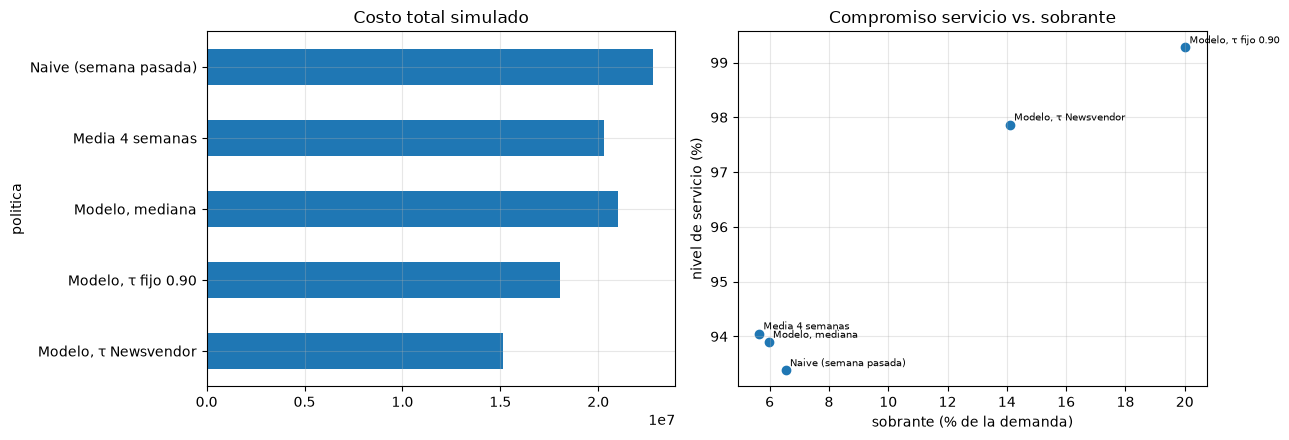

In [7]:
resumen = res.simulacion_resumen
display(resumen.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
resumen["costo_total"].plot.barh(ax=axes[0], color="tab:blue"); axes[0].invert_yaxis(); axes[0].set_title("Costo total simulado")
axes[1].scatter(resumen["sobrante_%_demanda"], 100 * resumen["nivel_de_servicio"])
for nombre, f in resumen.iterrows():
    axes[1].annotate(nombre, (f["sobrante_%_demanda"], 100 * f["nivel_de_servicio"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("sobrante (% de la demanda)"); axes[1].set_ylabel("nivel de servicio (%)"); axes[1].set_title("Compromiso servicio vs. sobrante")
plt.tight_layout(); plt.show()

**Lectura.** Las cifras son la suma de las 6 semanas simuladas (las semanas 8 a 13; las dos primeras del backtest se usan solo para calibrar los cuantiles), con los costos supuestos.

- **El Newsvendor es la política más barata:** costo total de 15.1 millones frente a 22.8 del naive, un ahorro de 33.6 %. También gana a las demás referencias: 25 % menos que la media de 4 semanas (20.3 millones) y 16 % menos que un nivel de servicio fijo de 0.90 (18.1 millones).
- **Mejor pronóstico no basta.** Pedir la mediana del modelo, sin colchón, cuesta 21.0 millones, algo más que la media de 4 semanas (20.3 millones), aunque el modelo se equivoque menos. Con costos asimétricos, el valor no está en el pronóstico central sino en elegir el cuantil correcto: quedarse corto cuesta más que pasarse en todos los productos (Cu de 2,400 a 3,700 frente a Co de 210 a 2,050).
- **El Newsvendor acepta algo de sobrante para evitar faltantes:** 14.1 % de la demanda en sobrante y 98 % de nivel de servicio, frente a 6.5 % de sobrante y 93 % de servicio del naive. Es más inventario, pero resulta más barato porque cada unidad faltante cuesta más que una sobrante.
- **Un nivel de servicio fijo de 0.90 casi elimina los faltantes (99 % de servicio) pero a un costo mayor:** sobrante de 20 % de la demanda. Aplica el mismo colchón a todos los productos, incluso a los que son caros de perder por merma, como el Jugo de Naranja. El Newsvendor ajusta el colchón por producto (τ de 0.64 a 0.92) y por eso baja el sobrante casi 6 puntos (de 20.0 % a 14.1 %) con un servicio similar (98 % frente a 99 %).
- **Alcance.** Es una comparación de políticas bajo los costos supuestos (α, β y márgenes), no una medición del costo real de Tostao. Todas las políticas se evalúan con los mismos Cu y Co con los que se optimiza el Newsvendor, así que su ventaja es la esperable si esos costos son correctos; si los costos reales fueran otros, la ventaja sería menor (o distinta). Cada semana se simula sin stock inicial, porque no hay historial de stock, y el sobrante se valora con Co y no pasa a la semana siguiente. La sensibilidad de la sección 4 muestra cuánto cambia el pedido con α y los demás supuestos.

## 4. Sensibilidad a los parámetros que no vienen en los datos

Se mueve un parámetro a la vez respecto del caso base y se mira cuánto cambia el pedido total y las ventas perdidas inevitables por el lead time (lo que se vende mientras llega el pedido y el stock no alcanza). Responde qué datos hay que conseguir primero.

,pedido_total_u,venta_perdida_inevitable_u,sku_sin_pedido,cambio_vs_base_%
escenario,,,,
Base,"15,453.000",376.500,2,0.000
Lead time 0,"13,555.000",0.000,3,-12.300
Lead time 2,"17,370.000","1,304.300",2,12.400
Lead time 3,"19,242.000","2,635.400",1,24.500
Lead time 7,"29,805.000","11,681.300",0,92.900
Revisión cada 3 días,"5,133.000",376.500,21,-66.800
En tránsito: 1 día de venta,"13,345.000",0.000,3,-13.600
En tránsito: 2 días de venta,"11,230.000",0.000,6,-27.300
MOQ y empaque de 6,"15,828.000",376.500,2,2.400


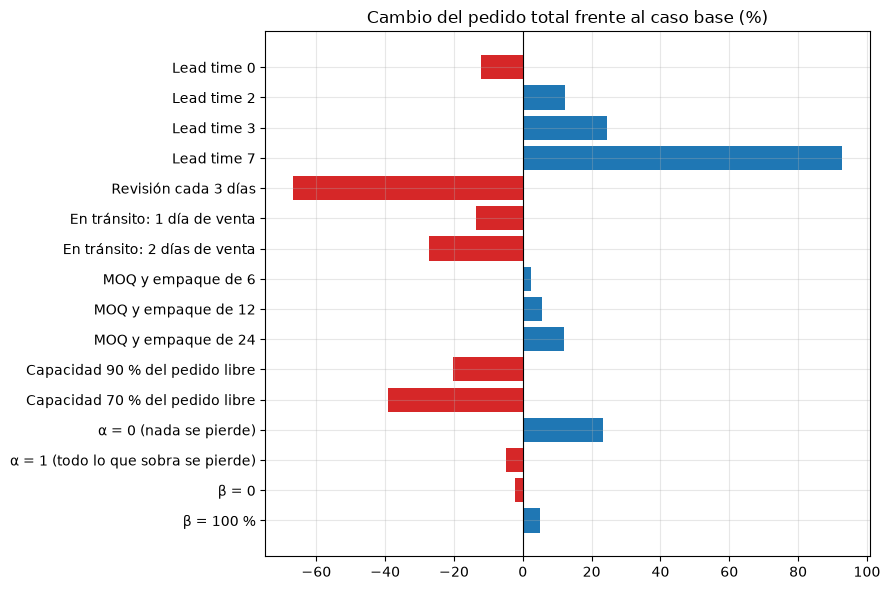

In [8]:
diario = res.pedido  # el pedido base ya usa el pronóstico diario y los cuantiles calibrados
from tostao_abastecimiento.features import construir_panel, dividir_historia_futuro
from tostao_abastecimiento.pipeline import pronosticar_semana
panel = construir_panel(datos)
sem = agregar_semanal(res.backtest, [MODELO_FINAL])
cal = CalibradorCuantiles().ajustar(sem["unidades_vendidas"], sem[MODELO_FINAL])
diario_fut, _ = pronosticar_semana(panel, datos, cal)

sens = tabla_sensibilidad(datos, params, diario_fut, IncertidumbreEmpirica(cal))
display(sens.round(1))

s_ = sens["cambio_vs_base_%"].iloc[1:]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(s_.index, s_.values, color=np.where(s_.values >= 0, "tab:blue", "tab:red")); ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_title("Cambio del pedido total frente al caso base (%)"); plt.tight_layout(); plt.show()

**Lectura.** Cada fila mueve un solo parámetro respecto del caso base (pedido total de 15,453 unidades) y muestra cuánto cambia el pedido. Es un cambio en cantidad pedida, no en costo; sirve para ver qué tan sensible es el pedido a cada supuesto y, por tanto, qué dato conviene conseguir primero.

- **El lead time mueve el pedido de forma directa.** Cada día más de lead time agrega ≈12 % al pedido (+12.4 % con 2 días, +24.5 % con 3) y quitarlo lo reduce 12.3 %. Con 7 días el pedido casi se duplica (+92.9 %), porque hay que cubrir 14 días de demanda en lugar de 8. Además crea **venta perdida inevitable**: lo que se vende mientras llega el pedido y el stock no alcanza no se recupera pidiendo más. Pasa de ≈377 unidades en el caso base a 1,304 con 2 días, 2,635 con 3 y 11,681 con 7.
- **El stock en tránsito reduce el pedido en la misma dirección:** 1 día de venta en camino lo baja 13.6 % (13,345 unidades) y 2 días lo bajan 27.3 %. Ignorarlo implica pedir de más.
- **α (cuánto se pierde de lo que sobra) es el supuesto de costo más influyente.** Si no se perdiera nada de lo que sobra (α = 0), el pedido sube 23.3 %; si se perdiera todo (α = 1), baja 5.0 %. Es un rango de ≈4,400 unidades que depende de un supuesto no medido, y por eso la merma real por producto es el dato más valioso para afinar el pedido.
- **El empaque mínimo y el MOQ suben el pedido de forma mecánica** (redondean hacia arriba): +2.4 % con 6 unidades, +5.7 % con 12 y +12.0 % con 24. Con 24 unidades el efecto ya es comparable a un día de lead time.
- **β, la venta cruzada, pesa poco:** −2.2 % si se ignora y +5.1 % si se pierde toda. No justifica esfuerzo de estimación fino en esta etapa.
- **Dos escenarios no son comparables de frente:** la **revisión cada 3 días** (−66.8 %) no es un ahorro, sino que cada pedido cubre 4 días en lugar de 8 (3 de revisión + 1 de lead time); se pediría con más frecuencia y en cantidades menores, y 21 SKU-tienda no necesitarían pedido porque el stock actual los cubre. Las **capacidades** (−20.4 % y −39.2 %) recortan el pedido por definición, a 90 % y 70 % del pedido libre; muestran cuánto se dejaría de pedir, no un efecto de la demanda.

**Qué dato pedir primero al negocio:** (1) el lead time real de cada proveedor y el stock en tránsito: cada día mueve ≈12 a 14 % del pedido y son datos fáciles de conseguir; (2) la merma real por producto, para reemplazar α: pasar de α = 0 a α = 1 reduce el pedido 22.9 % (de 19,046 a 14,682), pero requiere medirla; (3) MOQ, empaque y capacidad por tienda; y, en último lugar, (4) la venta cruzada. Estos efectos coinciden en magnitud con los estimados en el EDA (H13: α ≈ 22 %, tránsito de 1 día ≈ −14 %, lead time de +1 día ≈ +12 %, β y empaque ≈ 6 %).

## 5. Incertidumbre: normal frente a empírica

El pedido depende del cuantil de la demanda. Hay dos formas de calcularlo:

- **Normal:** pronóstico + z × desviación, con un coeficiente de variación diario fijo (0.31) y ruido independiente entre días. Es una suposición habitual en inventarios, por su sencillez.
- **Empírica:** se usa la distribución de la venta relativa (real ÷ pronóstico) observada en semanas anteriores, sin suponer una forma. Se prueba con una sola distribución y con una por terciles de volumen (la que usa el pedido).

Se comparan fuera de muestra: cada semana se calibra solo con las anteriores y se evalúan con dos métricas. La **cobertura** dice si el cuantil cubre lo prometido (el 90 % debe cubrir cerca del 90 % de las veces). La **pérdida de cuantil (pinball)** castiga de forma asimétrica el error de cada cuantil: para el nivel τ, quedarse corto cuesta τ por unidad y pasarse cuesta (1 − τ). Un intervalo demasiado ancho cubre siempre pero tiene mayor pérdida; por eso las dos métricas se leen juntas. Menor pérdida es mejor.

,metodo,nivel_nominal,cobertura_observada,error_de_cobertura,perdida_cuantil
0,normal,0.500,0.507,0.007,5.585
1,normal,0.800,0.745,-0.055,3.986
2,normal,0.900,0.842,-0.058,2.575
3,normal,0.950,0.893,-0.057,1.551
4,empirica_global,0.500,0.506,0.006,5.588
5,empirica_global,0.800,0.817,0.017,3.951
6,empirica_global,0.900,0.900,0.000,2.477
7,empirica_global,0.950,0.950,0.000,1.469
8,empirica_por_volumen,0.500,0.516,0.016,5.611
9,empirica_por_volumen,0.800,0.805,0.005,3.966


Pérdida de cuantil, mejora (%) frente a la normal (positivo = mejor que la normal):


metodo,empirica_global,empirica_por_volumen,normal
nivel_nominal,,,
0.500,-0.070,-0.480,0.000
0.800,0.870,0.490,0.000
0.900,3.800,4.120,0.000
0.950,5.270,6.080,0.000


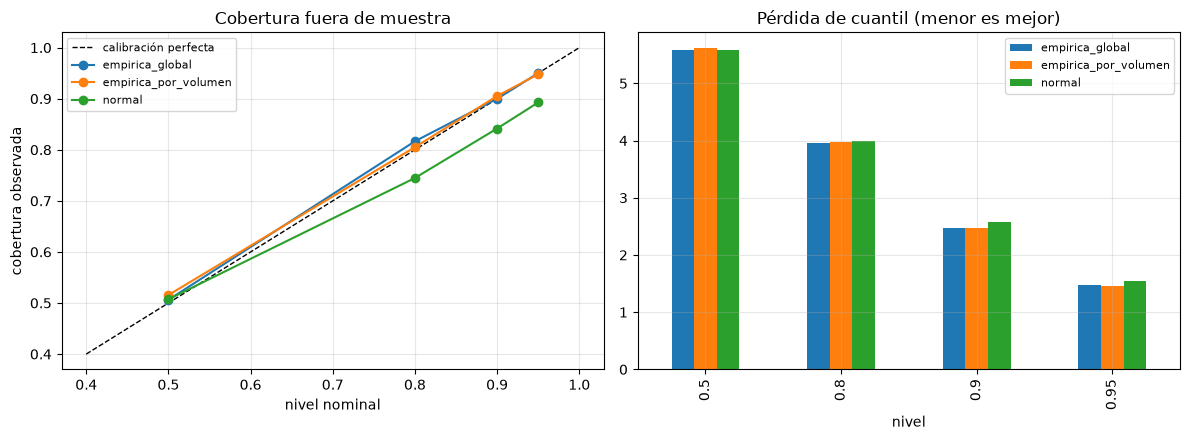

In [9]:
from tostao_abastecimiento.calibration import comparar_incertidumbre

comp_inc = comparar_incertidumbre(res.backtest, MODELO_FINAL)
display(comp_inc.round(4))

cob = comp_inc.pivot(index="nivel_nominal", columns="metodo", values="cobertura_observada")
per = comp_inc.pivot(index="nivel_nominal", columns="metodo", values="perdida_cuantil")
mejora = 100 * (1 - per.div(per["normal"], axis=0))
print("Pérdida de cuantil, mejora (%) frente a la normal (positivo = mejor que la normal):")
display(mejora.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0.4, 1], [0.4, 1], "k--", lw=1, label="calibración perfecta")
for m in cob.columns:
    axes[0].plot(cob.index, cob[m], "o-", label=m)
axes[0].set_xlabel("nivel nominal"); axes[0].set_ylabel("cobertura observada"); axes[0].legend(fontsize=8); axes[0].set_title("Cobertura fuera de muestra")
per.plot.bar(ax=axes[1]); axes[1].set_title("Pérdida de cuantil (menor es mejor)"); axes[1].set_xlabel("nivel"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.**

- **La normal queda corta en las colas.** Su cobertura fuera de muestra es 0.745, 0.842 y 0.893 para los niveles 0.8, 0.9 y 0.95: unos 5.5 a 5.8 puntos por debajo de lo prometido en los tres. Es decir, si se pide el cuantil 90 % con la normal, la demanda lo supera ≈16 % de las veces en lugar de 10 %, y habría más faltantes que los previstos. En el nivel 0.5 no hay diferencia (0.507), porque el centro de la distribución sí lo representa bien.
- **Las dos versiones empíricas quedan calibradas:** 0.817, 0.900 y 0.950 la global, y 0.805, 0.905 y 0.948 la de volumen, con errores de a lo sumo 1.7 puntos.
- **La pérdida de cuantil confirma la ventaja en las colas,** que es donde se decide el pedido (τ de 0.64 a 0.92). Frente a la normal, las empíricas la reducen 3.8 % y 4.1 % en el nivel 0.9 y 5.3 % y 6.1 % en el 0.95. En el nivel 0.8 la mejora es pequeña (≈0.5 % a 0.9 %) y en el 0.5 las empíricas son marginalmente peores (−0.1 % y −0.5 %), es decir, sin diferencia práctica.
- **Agrupar por volumen no aporta una mejora medible respecto de la empírica global.** Sus pérdidas son casi iguales (por ejemplo 2.469 frente a 2.477 en el nivel 0.9, y 1.456 frente a 1.469 en el 0.95), y la global es algo mejor en el 0.8. La diferencia está dentro del ruido. Se mantiene el calibrador por volumen porque el error relativo sí es mayor en los SKU de poca venta (sección 4 del notebook 02) y es la forma natural de ajustar el colchón, pero conviene decir que, con estos datos, el resultado agregado es equivalente.
- **Por qué la normal subestima.** Supone que el ruido de cada día es independiente, así que el error semanal se compensa. En la práctica una parte del error es común a toda la semana (el nivel de ventas de un SKU-tienda cambia, o el modelo se equivoca en el nivel), y eso hace que el error semanal real sea mayor que el que implica el supuesto. Es una explicación coherente con lo observado, no algo que se haya probado por separado.
- **Qué se concluye.** Para decidir el pedido se usa la distribución empírica: está calibrada, y es mejor en pérdida de cuantil en los niveles que importan. La normal quedaría como aproximación simple y rápida, con el riesgo de más faltantes de los esperados (ver el efecto en el pedido más abajo).

### Limitaciones de cada método

**Normal (CV diario fijo)**
- Impone una campana simétrica. La demanda son conteos no negativos y, con pocas unidades, es asimétrica: la normal puede dar cuantiles bajos o altos en los SKU de poca venta, y toca recortarla en cero.
- Usa el mismo coeficiente de variación para todos los SKU-tienda, aunque el error relativo cambia con el volumen (más alto en los de poca venta).
- Supone ruido independiente entre días; si hay semanas "buenas" o "malas" para todo el SKU, la incertidumbre semanal queda subestimada.
- A favor: es sencilla de explicar y de sensibilizar ("¿y si la volatilidad sube 20 %?"), y no necesita historia de errores.

**Empírica (calibrada con el backtest)**
- Necesita historia de errores: con 8 pliegues, los cuantiles muy altos (0.95, 0.99) se apoyan en pocas observaciones y son ruidosos.
- Supone que los errores futuros se parecerán a los pasados. Un festivo, una promoción o un pico de temporada no vistos en la historia dejan el colchón corto.
- No extrapola: no contempla eventos más extremos que los observados.
- Agrupa por volumen, no por SKU: no captura la volatilidad propia de cada producto-tienda.
- Está atada al modelo de pronóstico: si el modelo cambia, hay que recalibrar.
- A favor: no impone una forma, se ajusta a lo observado y se verifica con la cobertura fuera de muestra.

**Cómo se mitiga.** La cobertura y la pérdida de cuantil se miden siempre fuera de muestra; el calibrador exige un mínimo de observaciones por grupo; y una opción práctica es combinar ambas: empírica en el centro y normal en las colas.

### Efecto en el pedido

Los pedidos totales que resultan de usar cada método de incertidumbre, con el mismo pronóstico y los mismos parámetros:

In [10]:
ped_norm = calcular_pedido(datos, params, diario_fut, IncertidumbreNormal(params.cv_diario))
ped_emp = calcular_pedido(datos, params, diario_fut, IncertidumbreEmpirica(cal))
comp = pd.DataFrame({"pedido_total_u": {"Normal (CV diario 0.31)": ped_norm["pedido"].sum(), "Empírica (backtest)": ped_emp["pedido"].sum()}})
comp["diferencia_%"] = 100 * (comp["pedido_total_u"] / comp.iloc[0, 0] - 1)
display(comp.round(1))

,pedido_total_u,diferencia_%
Normal (CV diario 0.31),"15,035.000",0.000
Empírica (backtest),"15,453.000",2.800


**Lectura.** Con el mismo pronóstico y los mismos parámetros, la distribución empírica pide 15,453 unidades frente a 15,035 de la normal: 418 unidades más (+2.8 %). La diferencia total es pequeña, pero va en la dirección que muestra la cobertura: la normal subestima las colas (cubre ≈84 % cuando promete 90 %), así que pide menos de lo necesario y dejaría más faltantes de los previstos. La empírica pide algo más porque su colchón sí corresponde al nivel de servicio buscado.

## 6. Limitaciones y datos a pedir

- **Foto de stock sin historia.** No se puede evaluar la política actual ni simular el pedido neto en el backtest; la simulación supone que cada semana empieza sin stock.
- **Costos supuestos y evaluación a su favor.** La simulación evalúa todas las políticas con los mismos Cu y Co con los que se optimiza el Newsvendor; es una comparación bajo esos costos y cubre 6 semanas de backtest.
- **Parámetros declarados.** α, β, lead time, MOQ, capacidad y tránsito son supuestos; la sensibilidad muestra cuáles importan más.
- **Una sola semana de pronóstico y 13 de historia.** No hay estacionalidad mensual ni anual que aprender; el backtest tiene 8 pliegues.
- **Datos a pedir al negocio:** historial diario de stock, pedidos recibidos y mermas; lead time y calendario de entrega del proveedor; MOQ y empaque; capacidad por tienda; órdenes en tránsito; merma real por producto.

## 7. Recomendaciones para mejorar la optimización

1. **Historial diario de stock, pedidos recibidos y mermas.** Permite medir el α real (hoy es un supuesto), simular el pedido neto de stock en el backtest y evaluar la política actual.
2. **Lead time real y su variabilidad.** El lead time fijo es un supuesto; incorporar su incertidumbre en el horizonte cambia el cuantil que se necesita.
3. **Costos reales.** Validar Cu y Co con finanzas: costo de capital, costo de oportunidad de la venta perdida, costo real de merma y de almacenamiento.
4. **Optimización conjunta con restricciones.** MOQ por proveedor, volumen del camión o palet, capacidad por tienda y presupuesto, en lugar de aplicarlos después del Newsvendor por SKU.
5. **Venta cruzada por pares.** Usar la probabilidad condicional de cada par de productos (asimétrica, como mostró el EDA) en lugar de un margen cruzado general.
6. **Merma según vida útil.** Un modelo de varios periodos para perecederos, donde lo que sobra hoy se puede vender mañana con otra probabilidad de pérdida.
7. **Política de reposición continua.** Pasar de una revisión semanal a una política de punto de reorden y nivel máximo (s, S) cuando haya datos de stock diario.
8. **Segmentación ABC/XYZ.** Esfuerzo y nivel de servicio distintos según importancia en margen y variabilidad de la demanda.
9. **Piloto controlado.** Probar la política en algunas tiendas frente a la actual y medir faltantes, sobrantes y costo reales antes de extenderla.

## 8. Conclusiones de la optimización

- **Pedido de la semana 1–7 de abril.** Se recomiendan 15,453 unidades, que sumadas al stock actual (3,367) dejan 18,820 disponibles: 12 % sobre la demanda media del horizonte (16,742 unidades para 8 días: 7 de revisión y 1 de lead time). 158 de los 160 SKU-tienda necesitan pedido, coherente con la baja cobertura de stock que mostró el EDA (mediana de 1.4 días).
- **Valor del enfoque.** En la simulación de 6 semanas de backtest, la política Newsvendor es la más barata: 15.1 millones frente a 22.8 del naive (−33.6 %), 20.3 de la media de 4 semanas (−25 %) y 18.1 de un nivel de servicio fijo de 0.90 (−16 %). La ventaja viene de elegir el cuantil correcto por producto, no solo de pronosticar mejor: pedir la mediana del modelo cuesta algo más que la media de 4 semanas. Es una comparación bajo los costos supuestos, evaluada con los mismos Cu y Co que optimiza el Newsvendor.
- **Sensibilidad.** El pedido es sensible al lead time (≈12 % por día, con venta perdida inevitable que pasa de ≈377 a 1,304 unidades con 2 días), al stock en tránsito (−13.6 % con un día de venta) y a α (el pedido cae 22.9 % al pasar de α = 0 a α = 1). Pesan poco la venta cruzada (β) y, en menor medida, el empaque. Por eso lo primero que hay que pedir al negocio es el lead time y el tránsito reales, y luego la merma real por producto.
- **Incertidumbre.** La distribución empírica queda calibrada (cobertura de 0.900 o 0.905 en el nivel 0.9 y de 0.950 o 0.948 en el 0.95, según la versión) y reduce la pérdida de cuantil entre 4 % y 6 % frente a la normal en los niveles 0.9 y 0.95; la normal subestima las colas en ≈5.7 puntos y pide 2.8 % menos. Agrupar por volumen equivale a la versión global en el resultado agregado.
- **Límites.** Los costos (α, β) y el lead time son supuestos; la simulación parte de cada semana sin stock; el pronóstico se apoya en 13 semanas, sin estacionalidad anual ni calendario. Los ahorros comparan políticas bajo esos supuestos y no miden el costo real de Tostao.